# dsQTL benchmark 10: AlphaGenomeAtlas, EpiBERT and GM12878 model comparisons

Full **17,506-variant** Yoruba LCL benchmark, including all 435 positives. EpiBERT
job `13324012` completed with exit code 0 in 16:13:30. Predictions have shape
`(17506, 4092, 2)` (reference, alternate), ensemble-averaged across two checkpoints
and both sequence orientations; the central 1,536 bp of the ATAC input was masked.

This notebook retains the **12 non-HepG2 arms**, cached scoring definitions, merged
peak strata and common-support comparison from `dsQTL_benchmark9.ipynb`.
It reads existing arrays/caches without modifying them or launching inference.
Figures and tables are embedded in this notebook; no separate output files are written.

**Scoring:** the paper's EpiBERT effect is the alternate-minus-reference sum over
four central 128-bp bins, output indices `2044:2048`. Classification uses its
absolute value. The released helper incorrectly slices three bins (`2044:2047`).
The input mask is wider than the scoring window. Existing notebook arms use
absolute log2(ref/alt) on their original windows (Borzoi/Enformer: 2,048 bp), or
the cached ChromBPNet scores. Separate sensitivity panels show EpiBERT logFC at
512, 1,536 and 2,048 bp; these alternatives are exploratory, not selected as a new
primary score after observing results.

GM12878 is a training cell type for EpiBERT. Peak specificity strata do not by
themselves measure generalization to new cell types or matched cross-cell effects.
The original notebook annotation defines specificity from measured DNase tracks.

**AlphaGenomeAtlas extension:** this separate copy adds GM12878 DNase Atlas scores
as a new primary model named exactly `AlphaGenomeAtlas`. Its classification score
is the absolute native Atlas effect: `log2((sum(ALT)+1)/(sum(REF)+1))` over 501 bp
centered on the variant. The original `AlphaGenome` arm retains its saved 1,000-bp
window and no-pseudocount logFC, so the two primary arms differ in scoring as well
as their underlying predictions. A separate final panel compares the matched
501-bp, +1-pseudocount scores. No new inference or API requests are made.


In [1]:
from pathlib import Path
import ast
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

NOTEBOOK_DIR = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl')
CACHE = NOTEBOOK_DIR / 'dsQTL_benchmark8_cache'
DSQ = Path('/data1/lesliec/sarthak/data/joint_playground/dsQTL')
EPI_PATH = DSQ / 'epibert_dsqtl.npy'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Read ARMS as a literal: importing the old analysis module would load unrelated
# dependencies and its annotation function writes caches.
tree = ast.parse((NOTEBOOK_DIR / 'dsQTL_benchmark8_analysis.py').read_text())
ARMS = ast.literal_eval(next(node.value for node in tree.body
    if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == 'ARMS'
                                           for t in node.targets)))
manifest = json.loads((CACHE / 'scores_manifest.json').read_text())
assert json.loads(json.dumps(ARMS)) == manifest['arms']
assert hashlib.sha256((DSQ / 'filtered_dsqtls.txt').read_bytes()).hexdigest() == manifest['variants_sha256']
for item in manifest['files']:
    st = Path(item['path']).stat()
    assert st.st_size == item['size'] and st.st_mtime_ns == item['mtime_ns'], item['path']

q = pd.read_csv(DSQ / 'filtered_dsqtls.txt', sep='\t')
v = pd.read_csv(CACHE / 'variant_specificity.tsv.gz', sep='\t')
assert len(q) == len(v) == 17506
np.testing.assert_array_equal(v.variant_row, np.arange(len(q)))
np.testing.assert_array_equal(v.SNPname2, q.SNPname2)
np.testing.assert_array_equal(v.label_binary, (q.label == 1).astype(int))
with np.load(CACHE / 'model_scores.npz') as d:
    base_scores, base_scorable = d['scores'].copy(), d['scorable'].copy()
assert base_scores.shape == base_scorable.shape == (len(q), len(ARMS))
epi = np.load(EPI_PATH, mmap_mode='r')
assert epi.shape == (len(q), 4092, 2) and epi.dtype == np.float32
for start in range(0, len(epi), 1000):
    block = epi[start:start+1000]
    assert np.isfinite(block).all() and (block >= 0).all()
print(f'Validated full EpiBERT output: {epi.shape}, {epi.dtype}; cached arm provenance and variant row alignment.')

Validated full EpiBERT output: (17506, 4092, 2), float32; cached arm provenance and variant row alignment.


In [2]:
# Sum float64 after widening: avoid float32 reduction roundoff.
WINDOWS = {'512 bp': (2044, 2048), '1536 bp': (2040, 2052),
           '2048 bp': (2038, 2054)}
epi_scores, epi_support = {}, {}
for window, (lo, hi) in WINDOWS.items():
    totals = np.asarray(epi[:, lo:hi, :], dtype=np.float64).sum(axis=1)
    ok = (totals > 0).all(axis=1)
    key = f'EpiBERT logFC ({window})'
    score = np.full(len(q), np.nan)
    score[ok] = np.abs(np.log2(totals[ok, 1] / totals[ok, 0]))
    epi_scores[key], epi_support[key] = score, ok & np.isfinite(score)
    if window == '512 bp':
        EPI_PRIMARY = 'EpiBERT |delta| (512 bp, paper)'
        epi_scores[EPI_PRIMARY] = np.abs(totals[:, 1] - totals[:, 0])
        epi_support[EPI_PRIMARY] = np.isfinite(epi_scores[EPI_PRIMARY])

scores = {arm[0]: base_scores[:, i] for i, arm in enumerate(ARMS)}
scores.update(epi_scores)
names = [EPI_PRIMARY] + [arm[0] for arm in ARMS]

# Add Atlas after validating the original cache, without changing its ARMS manifest.
ATLAS_NAME = 'AlphaGenomeAtlas'
atlas_saved = pd.read_csv(DSQ / 'alphagenome_atlas_dsqtl/alphagenome_atlas_dsqtl.tsv', sep='\t')
assert len(atlas_saved) == len(q)
np.testing.assert_array_equal(atlas_saved.row_id, np.arange(len(q)))
np.testing.assert_array_equal(atlas_saved.SNPname2, q.SNPname2)
np.testing.assert_array_equal(atlas_saved.label, q.label)
np.testing.assert_array_equal(atlas_saved.source_allele1, q.allele1)
np.testing.assert_array_equal(atlas_saved.source_allele2, q.allele2)
assert atlas_saved.gm12878_dnase_status.eq('ok').all()
atlas_signed = atlas_saved.gm12878_dnase_score.to_numpy()
assert np.isfinite(atlas_signed).all()
scores[ATLAS_NAME] = np.abs(atlas_signed)
names.append(ATLAS_NAME)

# One fixed support shared across every primary and sensitivity result.
common = base_scorable.all(axis=1)
for supported in epi_support.values():
    common &= supported
y = v.label_binary.to_numpy()
specificity = v.merged_specificity.to_numpy()
MEDIAN = 68
peaks = pd.read_csv(CACHE / 'gm12878_merged.tsv.gz', sep='\t')
assert peaks.median_breadth.eq(MEDIAN).all()
np.testing.assert_array_equal(peaks.specificity,
    np.where(peaks.breadth <= MEDIAN, 'high_specificity', 'low_specificity'))
# Recompute cached labels in memory to validate the stratification.
check = np.full(len(v), 'outside_GM12878_peaks', dtype=object)
check[v.mapping_status != 'mapped'] = 'unmapped'
for chrom, rows in v[v.mapping_status == 'mapped'].groupby('chrom_hg38'):
    p = peaks[peaks.chrom == chrom].sort_values('start')
    if p.empty:
        continue
    pos = rows.pos0_hg38.to_numpy()
    idx = np.searchsorted(p.start.to_numpy(), pos, side='right') - 1
    ok = (idx >= 0) & (pos < p.end.to_numpy()[np.maximum(idx, 0)])
    check[rows.index.to_numpy()[ok]] = p.specificity.to_numpy()[idx[ok]]
np.testing.assert_array_equal(check, specificity)

masks = {'Overall': common,
         'Low specificity (>68 tracks)': common & (specificity == 'low_specificity'),
         'High specificity (≤68 tracks)': common & (specificity == 'high_specificity')}
counts = pd.DataFrame([{'Subset': group, 'Variants': int(mask.sum()),
    'Positives': int(y[mask].sum()), 'Negatives': int(mask.sum()-y[mask].sum()),
    'Chance AP': float(y[mask].mean())} for group, mask in masks.items()]).set_index('Subset')
print(f'Common support: {common.sum():,}/{len(q):,}; excluded: {(~common).sum():,}')
print(f'Outside annotated GM12878 peaks: {(common & (specificity == "outside_GM12878_peaks")).sum():,}')
display(counts)

def ap_table(selected_names):
    return pd.DataFrame({group: [average_precision_score(y[mask], scores[name][mask])
                               for name in selected_names]
                         for group, mask in masks.items()}, index=selected_names)

results = ap_table(names)
display(results.sort_values('Overall', ascending=False).round(4))
assert common.all(), 'The original full common support must remain unchanged.'
np.testing.assert_allclose(results.loc['AlphaGenome'], [.6263,.6412,.6036], atol=.000051, rtol=0)
np.testing.assert_allclose(results.loc[ATLAS_NAME], [.6469,.6560,.6888], atol=.000051, rtol=0)
print('Atlas row alignment, full support and AP checkpoints passed.')


Common support: 17,506/17,506; excluded: 0
Outside annotated GM12878 peaks: 5,333


,Variants,Positives,Negatives,Chance AP
Subset,,,,
Overall,17506,435,17071,0.024849
Low specificity (>68 tracks),11338,366,10972,0.032281
High specificity (≤68 tracks),834,38,796,0.045564


,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
AlphaGenomeAtlas,0.6469,0.6560,0.6888
AlphaGenome,0.6263,0.6412,0.6036
Enformer (pretrained),0.5786,0.5860,0.5424
ChromBPNet (GM12878 ATAC IPS),0.5639,0.5589,0.5992
cis-Mamba (GM12878 DNase logFC),0.5508,0.5473,0.6473
Borzoi LoRA (GM12878),0.5471,0.5415,0.5709
Borzoi (pretrained),0.5384,0.5373,0.5534
Borzoi full FT (GM12878),0.5356,0.5449,0.4807
Enformer retrained (GM12878),0.4904,0.4975,0.4205
ChromBPNet (GM12878 ATAC logFC),0.4901,0.4906,0.6121


Atlas row alignment, full support and AP checkpoints passed.


## Overall model comparison

All bars use the same common-support rows. The dotted line is positive prevalence
(chance average precision). EpiBERT uses the paper's absolute 512-bp difference;
the other models retain notebook 9's score definitions. AP is average precision,
not trapezoidal integration of a precision–recall curve.

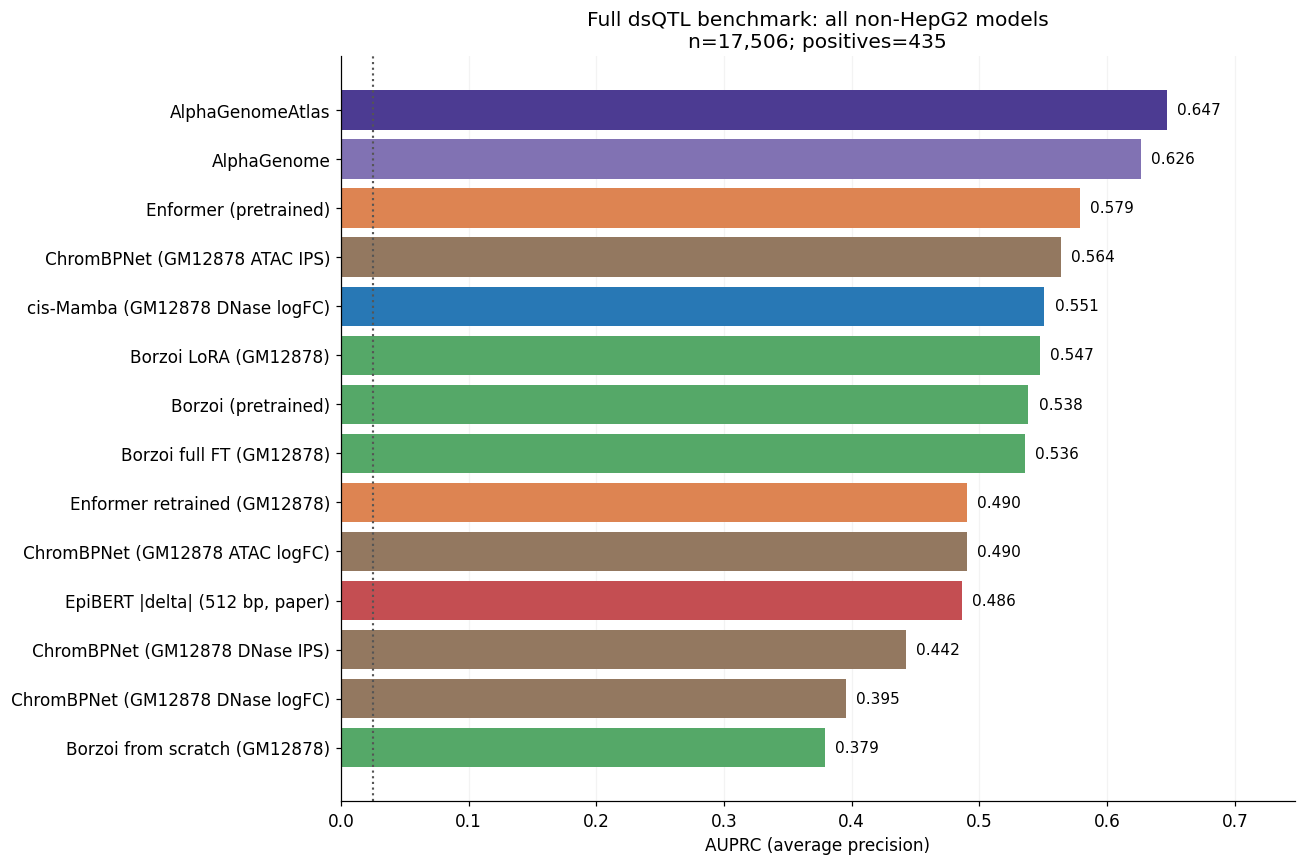

In [3]:
FAMILY_COLORS = {'ours': '#2878B5', 'enformer': '#DD8452', 'borzoi': '#55A868',
                 'alphagenome': '#8172B3', 'chrombpnet': '#937860'}
colors = {name: FAMILY_COLORS[family] for name, family, _ in ARMS}
colors[EPI_PRIMARY] = '#C44E52'
colors[ATLAS_NAME] = '#4C3B92'
for name in epi_scores:
    colors[name] = '#C44E52'

def bars(ax, table, group, order, title):
    vals = table.loc[order, group].to_numpy()
    ax.barh(np.arange(len(order)), vals, color=[colors[n] for n in order])
    ax.set_yticks(np.arange(len(order)), order)
    ax.invert_yaxis()
    ax.axvline(counts.loc[group, 'Chance AP'], color='#555555', ls=':', lw=1.4)
    ax.set_xlim(0, min(1, max(.1, float(vals.max())+.10)))
    for i, value in enumerate(vals):
        ax.text(value+.008, i, f'{value:.3f}', va='center', fontsize=10)
    ax.set_xlabel('AUPRC (average precision)')
    ax.set_title(f'{title}\nn={int(counts.loc[group, "Variants"]):,}; positives={int(counts.loc[group, "Positives"])}')
    ax.grid(axis='x', alpha=.15)
    ax.set_axisbelow(True)

order = results.sort_values('Overall', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(12, 8))
bars(ax, results, 'Overall', order, 'Full dsQTL benchmark: all non-HepG2 models')
fig.tight_layout()
plt.show()

## Differences by peak specificity

Merged GM12878 DNase peaks are classified by their breadth across the original
track panel. High specificity means breadth ≤68; low specificity means >68.
Variants outside those peaks remain in the overall analysis but do not enter
either specificity panel. Each group has its own positive prevalence.

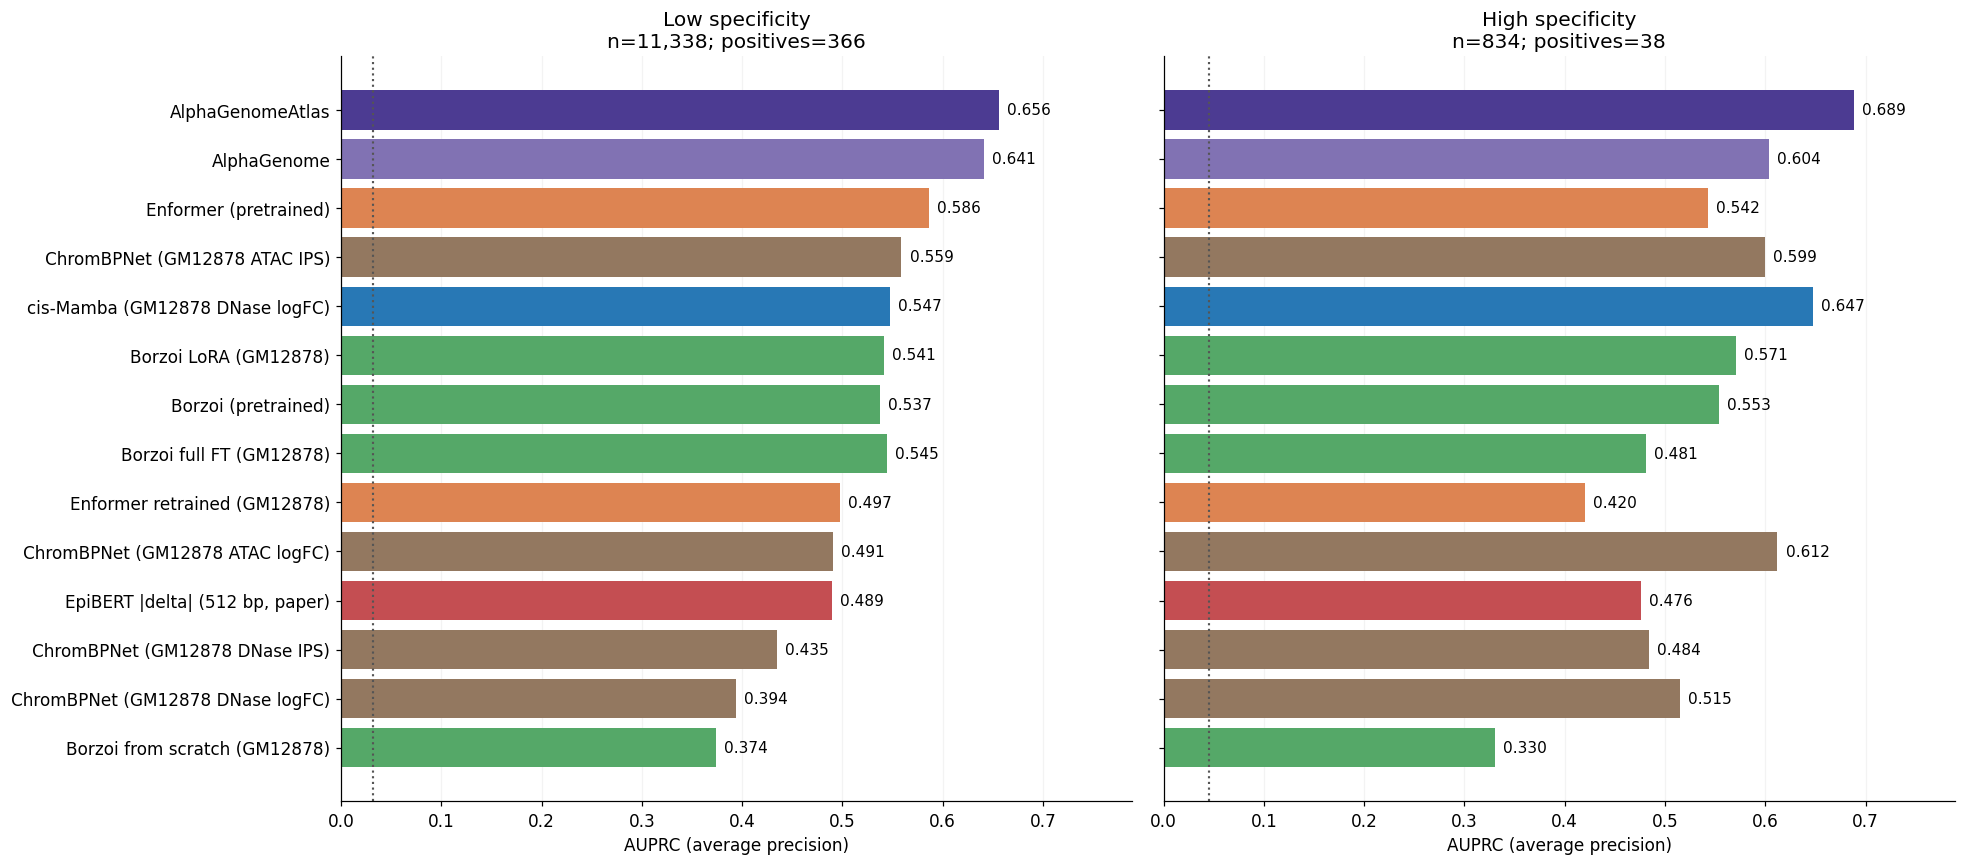

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True)
for ax, group, title in zip(axes, list(masks)[1:], ['Low specificity', 'High specificity']):
    bars(ax, results, group, order, title)
axes[1].tick_params(labelleft=False)
axes[0].set_xlim(0, min(1, results.iloc[:, 1:].to_numpy().max()+.10))
fig.tight_layout()
plt.show()

## Precision–recall curves

Selected principal models use their original scores; the legend includes each
panel's AP. The prevalence line varies by subset. High specificity has relatively
few positives, so apparent differences need uncertainty estimates.

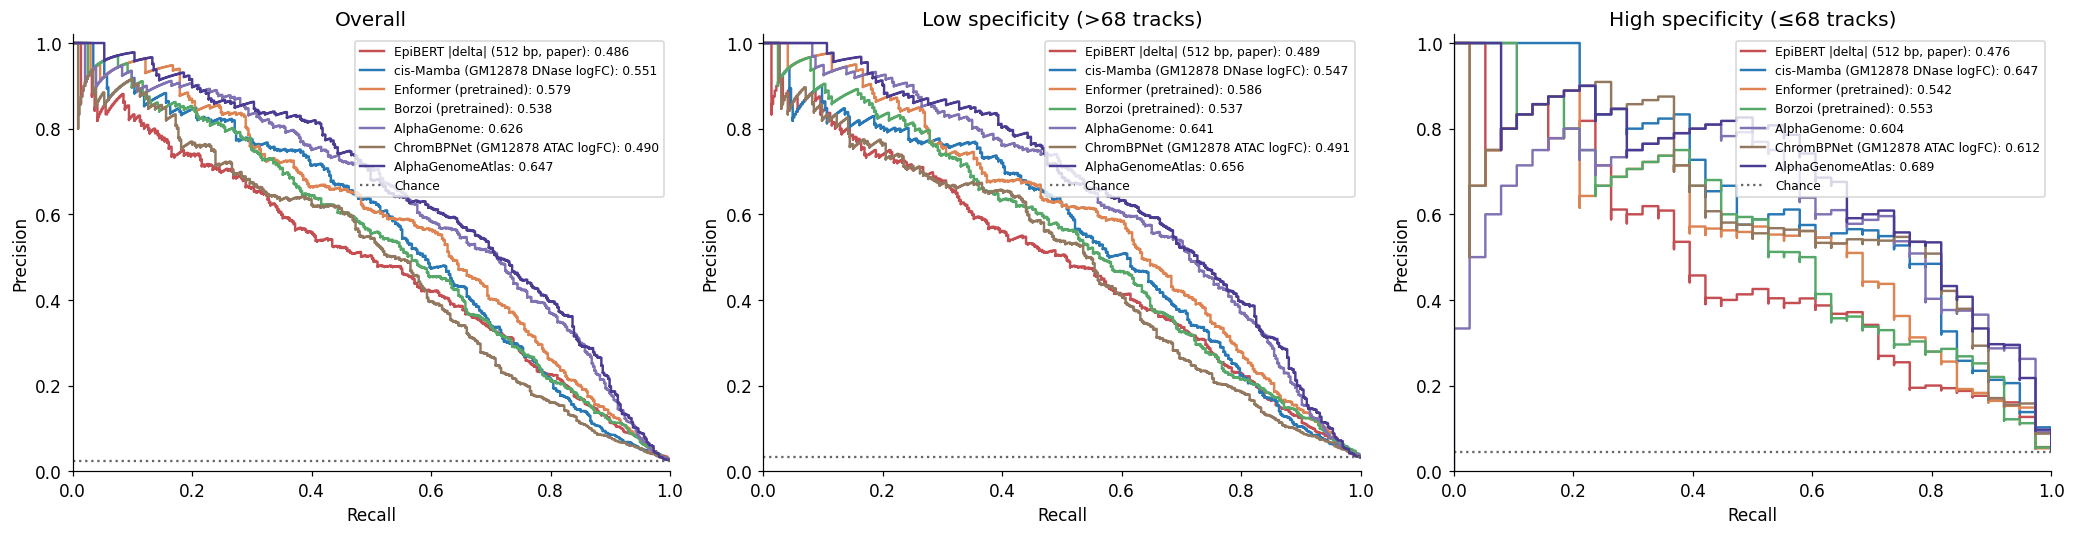

In [5]:
curve_names = [EPI_PRIMARY, ARMS[0][0], ARMS[1][0], ARMS[3][0], ARMS[7][0], ARMS[10][0]]
curve_names.append(ATLAS_NAME)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (group, mask) in zip(axes, masks.items()):
    for name in curve_names:
        precision, recall, _ = precision_recall_curve(y[mask], scores[name][mask])
        ax.step(recall, precision, where='post', color=colors[name], lw=1.6,
                label=f'{name}: {results.loc[name, group]:.3f}')
    ax.axhline(y[mask].mean(), color='#666666', ls=':', label='Chance')
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall', ylabel='Precision', title=group)
    ax.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

## EpiBERT scoring sensitivity

The primary paper score stays fixed. LogFC scores normalize the change by predicted
level and can rank variants differently. The 2,048-bp option matches the window
width used by the notebook's Enformer/Borzoi arms, though their predicted assays
and model inputs still differ. The 1,536-bp option covers the entire ATAC mask.

,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
"EpiBERT |delta| (512 bp, paper)",0.4862,0.4892,0.4758
EpiBERT logFC (512 bp),0.4269,0.4428,0.4902
EpiBERT logFC (1536 bp),0.4590,0.4702,0.5153
EpiBERT logFC (2048 bp),0.4715,0.4808,0.5202
cis-Mamba (GM12878 DNase logFC),0.5508,0.5473,0.6473
Enformer (pretrained),0.5786,0.5860,0.5424
Borzoi (pretrained),0.5384,0.5373,0.5534
AlphaGenome,0.6263,0.6412,0.6036
AlphaGenomeAtlas,0.6469,0.6560,0.6888


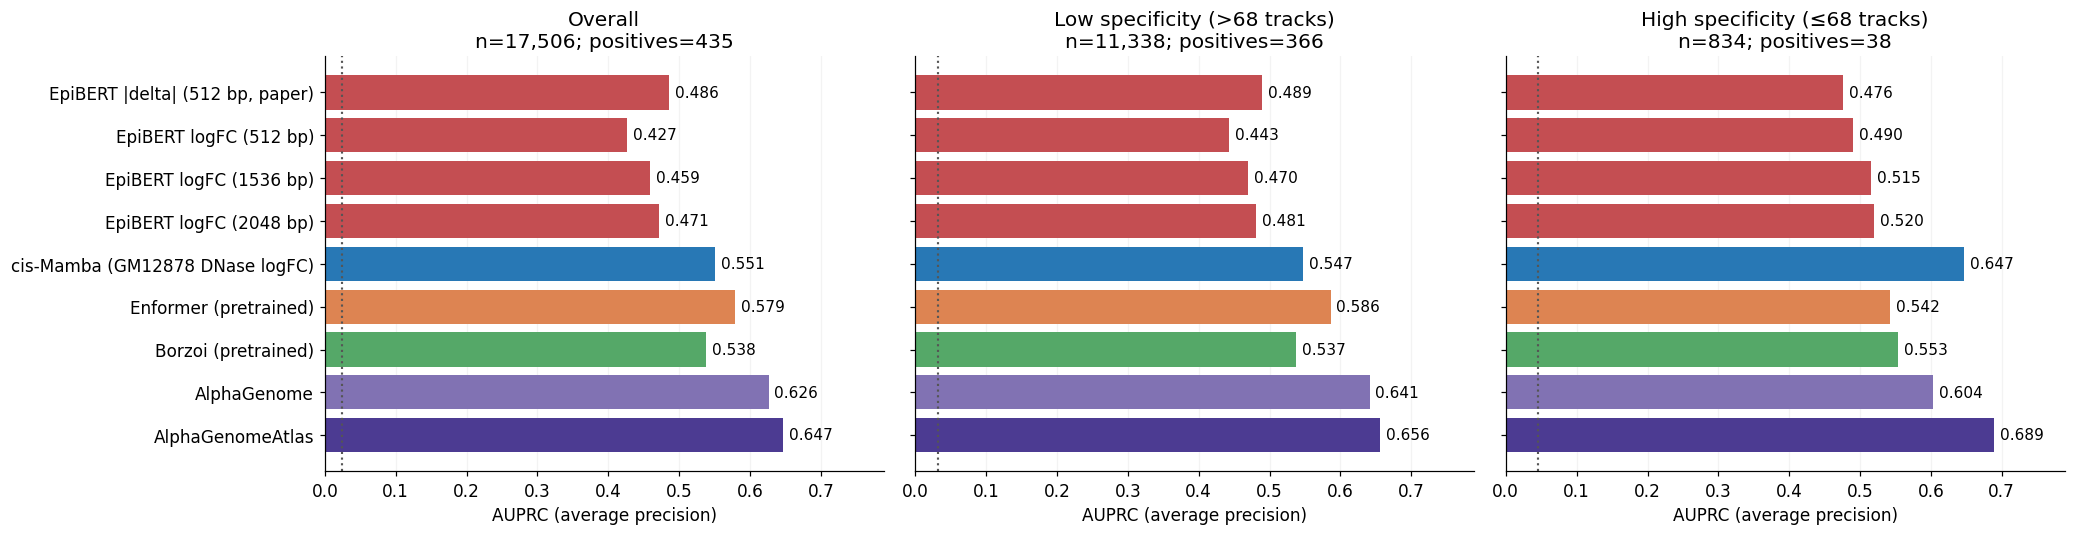

In [6]:
sensitivity_names = [EPI_PRIMARY, 'EpiBERT logFC (512 bp)', 'EpiBERT logFC (1536 bp)',
                     'EpiBERT logFC (2048 bp)', ARMS[0][0], ARMS[1][0], ARMS[3][0], ARMS[7][0]]
sensitivity_names.append(ATLAS_NAME)
sensitivity = ap_table(sensitivity_names)
display(sensitivity.round(4))
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharex=True)
for ax, group in zip(axes, masks):
    bars(ax, sensitivity, group, sensitivity_names, group)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
axes[0].set_xlim(0, min(1, sensitivity.to_numpy().max()+.10))
fig.tight_layout()
plt.show()

## Paired uncertainty: cis-Mamba minus EpiBERT

The bootstrap resamples merged peak clusters, using the same draws for the two
models; variants outside annotated peaks use chromosome/128-bp-bin clusters.
These descriptive percentile intervals use 300 draws. They do not account for
training leakage, choosing among alternative scores, or all possible model comparisons.
A positive AP gap favors cis-Mamba.

In [7]:
rng = np.random.default_rng(42)
N_BOOT = 300
bootstrap_rows = []
for group, mask in masks.items():
    idx = np.flatnonzero(mask)
    cluster = v.iloc[idx].merged_peak_id.fillna('').to_numpy().astype(str)
    fallback = (v.iloc[idx].chrom_hg38 + ':' + v.iloc[idx].bin_index.astype(str)).to_numpy()
    cluster = np.where(cluster == '', fallback, cluster)
    unique, inverse = np.unique(cluster, return_inverse=True)
    members = [np.flatnonzero(inverse == i) for i in range(len(unique))]
    draws = []
    for _ in range(N_BOOT):
        selected = np.concatenate([members[j] for j in rng.integers(0, len(unique), len(unique))])
        rows = idx[selected]
        if np.unique(y[rows]).size != 2:
            continue
        draws.append(average_precision_score(y[rows], scores[ARMS[0][0]][rows]) -
                     average_precision_score(y[rows], scores[EPI_PRIMARY][rows]))
    low, high = np.percentile(draws, [2.5, 97.5])
    bootstrap_rows.append({'Subset': group, 'cis-Mamba minus EpiBERT AP': results.loc[ARMS[0][0], group]-results.loc[EPI_PRIMARY, group],
                           '95% lower': low, '95% upper': high, 'Clusters': len(unique), 'Valid draws': len(draws)})
paired = pd.DataFrame(bootstrap_rows).set_index('Subset')
display(paired.round(4))

,cis-Mamba minus EpiBERT AP,95% lower,95% upper,Clusters,Valid draws
Subset,,,,,
Overall,0.0646,0.0211,0.1118,16447,300
Low specificity (>68 tracks),0.0582,0.0022,0.1148,10357,300
High specificity (≤68 tracks),0.1716,0.0219,0.3067,805,300


The finished dataset contains additional negatives relative to the interim snapshot.
Use these full results for model comparisons. High-specificity performance means
dsQTL detection within these annotated peaks; accurate context specificity needs
comparisons with measured effects under multiple cell types.

## AlphaGenome versus Atlas: matching the score definition

The original arm above uses 1,000 bp without a pseudocount. Below, the saved
AlphaGenome output is restricted to the central 501 bp and scored with the same
+1 pseudocount as Atlas. This isolates the remaining prediction differences from
window and pseudocount differences. The matched scores were computed from all
17,506 saved profiles, without inference, by `dsQTL_ag_501_benchmark.py`.


,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
AlphaGenome: matched 501 bp + pseudocount,0.6432,0.6547,0.6281
AlphaGenomeAtlas,0.6469,0.6560,0.6888


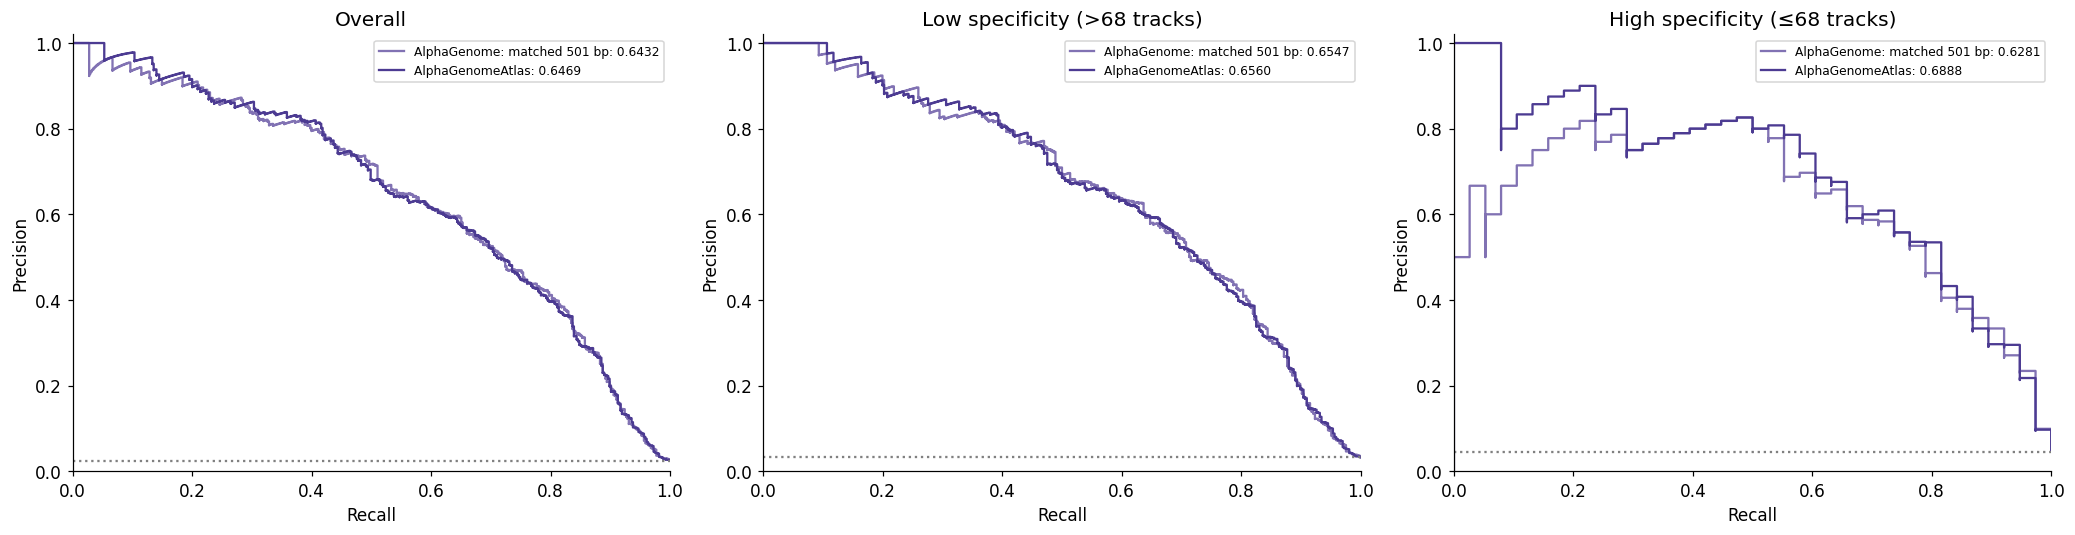

In [8]:
matched = pd.read_csv('/data1/lesliec/sarthak/alphagenome/api/logs/dsqtl_ag_501_benchmark/per_variant_scores.tsv', sep='\t')
np.testing.assert_array_equal(matched.row_id, np.arange(len(q)))
np.testing.assert_array_equal(matched.rsid, q.SNPname2)
np.testing.assert_array_equal(matched.label, y)
np.testing.assert_allclose(matched.atlas_native, atlas_signed, atol=1e-14, rtol=1e-12)
matched_old = np.abs(matched.original_501_atlas_formula.to_numpy())
matched_results = pd.DataFrame({
    group: [average_precision_score(y[mask], matched_old[mask]), results.loc[ATLAS_NAME, group]]
    for group, mask in masks.items()
}, index=['AlphaGenome: matched 501 bp + pseudocount', ATLAS_NAME])
display(matched_results.round(4))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (group, mask) in zip(axes, masks.items()):
    for name, values, color in [('AlphaGenome: matched 501 bp', matched_old, colors['AlphaGenome']),
                                 (ATLAS_NAME, scores[ATLAS_NAME], colors[ATLAS_NAME])]:
        precision, recall, _ = precision_recall_curve(y[mask], values[mask])
        ap = average_precision_score(y[mask], values[mask])
        ax.step(recall, precision, where='post', color=color, label=f'{name}: {ap:.4f}')
    ax.axhline(y[mask].mean(), color='gray', ls=':')
    ax.set(xlim=(0,1), ylim=(0,1.02), xlabel='Recall', ylabel='Precision', title=group)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The cell-type-specific subset contains 834 variants and 38 positives. A high
correlation across score magnitudes does not ensure identical ordering at the top
of the list. For example, the negative rs4295943 ranks first in the matched saved
AlphaGenome scores and 14th in Atlas. The top 20 contain 16 positives under each
method, and the top 50 contain 28 under each; their ordering differs.

A separate paired bootstrap of the original merged-peak clusters (2,000 draws,
seed 42) gives a 95% percentile interval of approximately −0.0036 to +0.1160 for
the matched-501-bp Atlas-minus-AlphaGenome AP gap. This small subset does not
establish a robust general improvement from the observed +0.0607 gap alone.
The source of the remaining per-variant prediction differences has not been
isolated by these saved-output comparisons.


## Accessibility cutoff sweep: specific versus general

At each integer cutoff **k**, specific means **GM12878 peak breadth ≤ k** and
general means **breadth > k**. Both groups are restricted to annotated GM12878
merged peaks on the notebook's fixed common model support. Outside-peak variants
do not enter either group. Breadth counts **accessible tracks**, including
replicates, rather than distinct biological cell types.

The shared x axis decreases from the full panel size to 1 (log spacing exposes
the small cutoffs). Every integer cutoff is evaluated; connected lines are not
a fitted smoother. Counts above **each panel** show its positive and negative
variants at selected cutoffs. The full counts and scores are saved as TSV files.
The original cutoff, 68, is marked. AUPRC here is **average precision**, as in
the rest of this notebook; its prevalence baseline varies with the cutoff.

These are nested subsets, not independent holdouts. Dotted model segments have
fewer than 20 positives or 20 negatives; this is a display flag, not a power
criterion. Single-class/empty groups have undefined AP and are left blank.
This descriptive sweep has no confidence bands and does not establish a
significant trend. Uncertainty would require paired locus/peak resampling.

Run the notebook's initial data/scoring cells (1 and 2), then the cells below.
Only cached scores are used. The default lines are the seven principal models
from the earlier PR comparison; edit `SWEEP_MODELS` to select other cached arms.


In [3]:
from time import perf_counter

sweep_started = perf_counter()
SWEEP_MODELS = [EPI_PRIMARY, ARMS[0][0], ARMS[1][0], ARMS[3][0],
                ARMS[7][0], ARMS[10][0], ATLAS_NAME]
SWEEP_MIN_CLASS_COUNT = 20  # display flag only; scores/counts are retained
SWEEP_OUT = NOTEBOOK_DIR / 'dsQTL_benchmark11_cutoff_sweep'
SWEEP_OUT.mkdir(exist_ok=True)

sweep_track_count = len(pd.read_csv(CACHE / 'tracks.tsv', sep='\t'))
sweep_breadth = pd.to_numeric(v.merged_breadth, errors='coerce').to_numpy()
sweep_in_peak = v.merged_peak_id.fillna('').ne('').to_numpy()
sweep_support = common & sweep_in_peak
assert np.isfinite(sweep_breadth[sweep_support]).all()
assert (sweep_breadth[sweep_support] == np.floor(sweep_breadth[sweep_support])).all()
assert ((sweep_breadth[sweep_support] >= 1) &
        (sweep_breadth[sweep_support] <= sweep_track_count)).all()
assert len(SWEEP_MODELS) == len(set(SWEEP_MODELS))
assert set(SWEEP_MODELS).issubset(scores)
for name in SWEEP_MODELS:
    assert np.isfinite(scores[name][sweep_support]).all(), name

# Check this sweep's membership against the earlier binary analysis, not merely
# its group sizes. This catches differing peak definitions or support masks.
np.testing.assert_array_equal(sweep_support & (sweep_breadth <= MEDIAN),
                              masks['High specificity (≤68 tracks)'])
np.testing.assert_array_equal(sweep_support & (sweep_breadth > MEDIAN),
                              masks['Low specificity (>68 tracks)'])

sweep_count_rows, sweep_score_rows = [], []
for cutoff in range(1, sweep_track_count + 1):
    for group, mask in [('Specific', sweep_support & (sweep_breadth <= cutoff)),
                        ('General', sweep_support & (sweep_breadth > cutoff))]:
        n = int(mask.sum())
        positive = int(y[mask].sum())
        negative = n - positive
        defined = positive > 0 and negative > 0
        sufficient_display_count = min(positive, negative) >= SWEEP_MIN_CLASS_COUNT
        sweep_count_rows.append(dict(cutoff=cutoff, group=group, variants=n,
            positives=positive, negatives=negative,
            prevalence=positive / n if n else np.nan,
            ap_defined=defined, low_count=not sufficient_display_count,
            peak_clusters=int(v.loc[mask, 'merged_peak_id'].nunique())))
        for name in SWEEP_MODELS:
            ap = average_precision_score(y[mask], scores[name][mask]) if defined else np.nan
            sweep_score_rows.append(dict(cutoff=cutoff, group=group, model=name, ap=ap))

sweep_counts = pd.DataFrame(sweep_count_rows)
sweep_results = pd.DataFrame(sweep_score_rows).merge(
    sweep_counts, on=['cutoff', 'group'], validate='many_to_one')
# Every cutoff partitions exactly the same in-peak population.
assert sweep_counts.groupby('cutoff').variants.sum().eq(sweep_support.sum()).all()
assert sweep_counts.groupby('cutoff').positives.sum().eq(int(y[sweep_support].sum())).all()
for group, old_group in [('Specific', 'High specificity (≤68 tracks)'),
                         ('General', 'Low specificity (>68 tracks)')]:
    at_original = sweep_results.query('cutoff == @MEDIAN and group == @group').set_index('model')
    np.testing.assert_allclose(at_original.loc[SWEEP_MODELS, 'ap'],
                              results.loc[SWEEP_MODELS, old_group], rtol=0, atol=1e-12)

sweep_counts.to_csv(SWEEP_OUT / 'cutoff_counts.tsv', sep='\t', index=False)
sweep_results.to_csv(SWEEP_OUT / 'cutoff_model_ap.tsv', sep='\t', index=False)
(SWEEP_OUT / 'config.json').write_text(json.dumps({
    'models': SWEEP_MODELS, 'cutoffs': [1, sweep_track_count],
    'specific_rule': 'GM12878 merged peak breadth <= cutoff',
    'general_rule': 'GM12878 merged peak breadth > cutoff',
    'support': 'existing notebook common support, within annotated GM12878 merged peaks',
    'annotation': str(CACHE / 'variant_specificity.tsv.gz'),
    'metric': 'sklearn.metrics.average_precision_score',
    'original_cutoff': MEDIAN, 'low_count_display_threshold_per_class': SWEEP_MIN_CLASS_COUNT,
    'confidence_intervals': False,
}, indent=2) + '\n')
SWEEP_COUNT_TICKS = sorted({1, 5, 20, MEDIAN, 200, sweep_track_count})
display(sweep_counts[sweep_counts.cutoff.isin(SWEEP_COUNT_TICKS)]
        .sort_values(['group', 'cutoff'], ascending=[False, False]))
print(f'Computed {sweep_track_count:,} cutoffs for {len(SWEEP_MODELS)} models in '
      f'{perf_counter() - sweep_started:.1f} s. '
      f'Fixed population: {sweep_support.sum():,} variants, '
      f'{int(y[sweep_support].sum()):,} positives. Outputs: {SWEEP_OUT}')


,cutoff,group,variants,positives,negatives,prevalence,ap_defined,low_count,peak_clusters
1346,674,Specific,12172,404,11768,0.033191,True,False,11162
398,200,Specific,6417,153,6264,0.023843,True,False,5904
134,68,Specific,834,38,796,0.045564,True,False,805
38,20,Specific,95,6,89,0.063158,True,True,94
8,5,Specific,4,0,4,0.000000,False,True,4
0,1,Specific,0,0,0,NaN,False,True,0
1347,674,General,0,0,0,NaN,False,True,0
399,200,General,5755,251,5504,0.043614,True,False,5258
135,68,General,11338,366,10972,0.032281,True,False,10357
39,20,General,12077,398,11679,0.032955,True,False,11068


Computed 674 cutoffs for 7 models in 15.8 s. Fixed population: 12,172 variants, 404 positives. Outputs: /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/dsQTL_benchmark11_cutoff_sweep


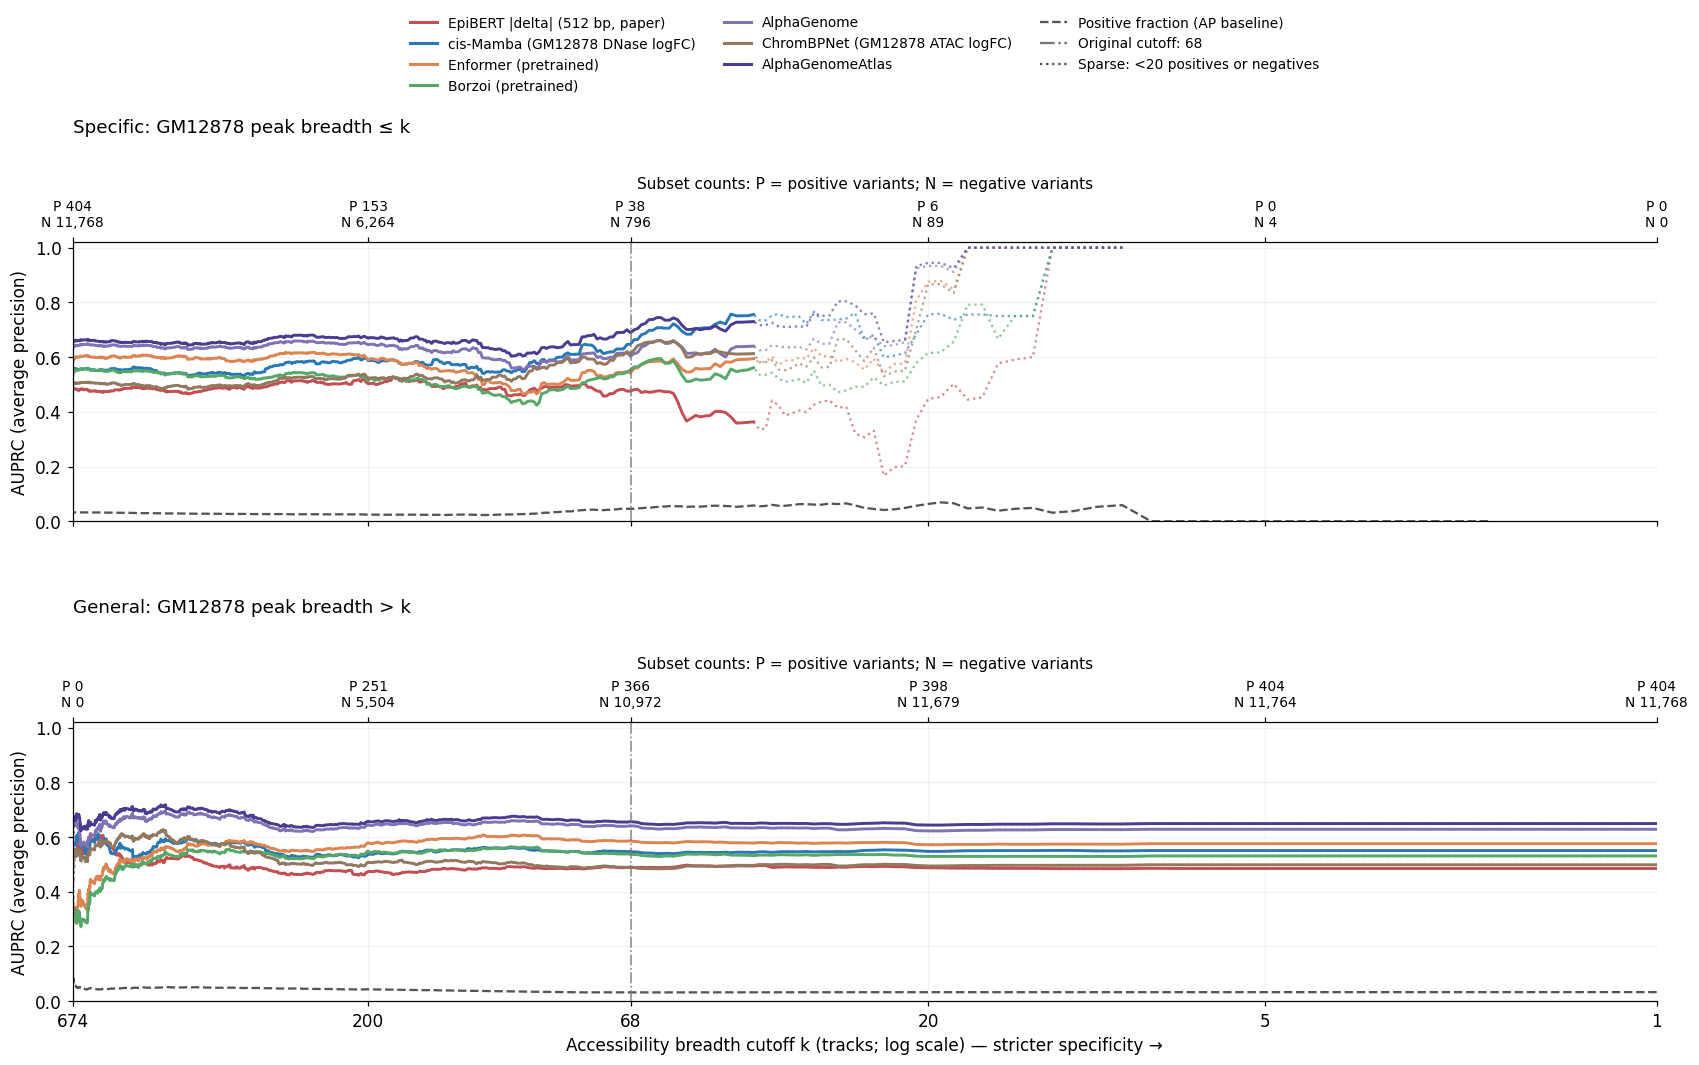

In [4]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from matplotlib.lines import Line2D

# Preserve the principal model colors used earlier in this notebook.
sweep_family_colors = {'ours': '#2878B5', 'enformer': '#DD8452',
                       'borzoi': '#55A868', 'alphagenome': '#8172B3',
                       'chrombpnet': '#937860'}
sweep_colors = {name: sweep_family_colors[family] for name, family, _ in ARMS}
sweep_colors.update({EPI_PRIMARY: '#C44E52', ATLAS_NAME: '#4C3B92'})
fig, sweep_axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True, sharey=True)
fig.subplots_adjust(left=.08, right=.98, bottom=.09, top=.78, hspace=.72)

for ax, group, rule in zip(sweep_axes, ['Specific', 'General'], ['≤ k', '> k']):
    count = sweep_counts[sweep_counts.group == group].sort_values('cutoff').set_index('cutoff')
    for name in SWEEP_MODELS:
        data = sweep_results[(sweep_results.group == group) &
                             (sweep_results.model == name)].sort_values('cutoff')
        # A faint dotted trace displays supported but sparse estimates; the
        # solid overlay identifies portions with >=20 observations per class.
        ax.plot(data.cutoff, data.ap, color=sweep_colors[name], lw=1.5,
                ls=':', alpha=.65)
        ax.plot(data.cutoff, data.ap.where(~data.low_count),
                color=sweep_colors[name], lw=1.9, label=name)
    ax.plot(count.index, count.prevalence, color='#555555', ls='--', lw=1.5)
    ax.axvline(MEDIAN, color='#777777', ls='-.', lw=1.1, alpha=.8)
    ax.set_xscale('log')
    ax.set_xlim(sweep_track_count, 1)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel('AUPRC (average precision)')
    ax.set_title(f'{group}: GM12878 peak breadth {rule}', loc='left', pad=72, fontsize=12)
    ax.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    ax.xaxis.set_major_formatter(FixedFormatter([str(k) for k in SWEEP_COUNT_TICKS]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(alpha=.15)
    ax.set_axisbelow(True)
    count_axis = ax.secondary_xaxis('top')
    count_axis.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    count_axis.xaxis.set_major_formatter(FixedFormatter([
        f'P {int(count.loc[k, "positives"]):,}\nN {int(count.loc[k, "negatives"]):,}'
        for k in SWEEP_COUNT_TICKS]))
    count_axis.xaxis.set_minor_locator(NullLocator())
    count_axis.tick_params(axis='x', labelsize=9, pad=5)
    count_axis.set_xlabel('Subset counts: P = positive variants; N = negative variants',
                          fontsize=10, labelpad=7)

sweep_axes[-1].set_xlabel('Accessibility breadth cutoff k (tracks; log scale) — stricter specificity →')
handles = [Line2D([], [], color=sweep_colors[n], lw=2, label=n) for n in SWEEP_MODELS]
handles += [Line2D([], [], color='#555555', ls='--', label='Positive fraction (AP baseline)'),
            Line2D([], [], color='#777777', ls='-.', label='Original cutoff: 68'),
            Line2D([], [], color='#555555', ls=':', label='Sparse: <20 positives or negatives')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.53, .997),
           ncol=3, fontsize=9, frameon=False)
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.png', dpi=180, bbox_inches='tight')
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.pdf', bbox_inches='tight')
plt.show()
